## 0. Setup

In [14]:
from pathlib import Path
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None) # 열이 많아도 생략 없이 다 보이게 설정


RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

# 그래프 형태 지정
BLUE = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

print("Raw files:", sorted(p.name for p in RAW_DIR.glob("*.csv"))) # p는 전체 경로, 파일 이름만 출력

Raw files: ['gfsteps.csv', 'jbsteps.csv', 'suggestions.csv', 'users.csv']


In [3]:
sugg = pd.read_csv(RAW_DIR / "suggestions.csv", low_memory=False)
users = pd.read_csv(RAW_DIR / "users.csv")
jb = pd.read_csv(RAW_DIR / "jbsteps.csv")
gf = pd.read_csv(RAW_DIR / "gfsteps.csv")

# 행x열 갯수
for name, df in [("suggestions", sugg), ("users", users), ("jbsteps", jb), ("gfsteps", gf)]:
    print(f"{name:<12} {df.shape[0]:>8,} rows x {df.shape[1]:>3} columns | users: {df['user.index'].nunique()}")

suggestions     8,274 rows x  86 columns | users: 37
users              37 rows x 117 columns | users: 37
jbsteps       237,865 rows x  10 columns | users: 37
gfsteps       197,524 rows x   7 columns | users: 27


## 1. suggestion.csv: Decision Points
Each row is one decision point for one user: whether a notification was sent (randomized five times a day), the context at that moment, the response, and step counts before and after.

### 1-1. Preview and column types

In [8]:
sugg = pd.read_csv(RAW_DIR / "suggestions.csv", low_memory=False) # 저장
print(sugg.shape) # 행열 개수
sugg.head() 

(8274, 86)


,user.index,decision.index,decision.index.nogap,sugg.select.utime,sugg.select.slot,sugg.select.update,sugg.tz,sugg.gmtoff,sugg.decision.utime,sugg.decision.slot,sugg.context.utime,sugg.response.utime,sugg.device.utime,sugg.device.since,interaction.count,connect,is.randomized,snooze.status,intransit,avail,send,send.active,send.sedentary,is.prefetch,recognized.activity,recognized.activity.response,tag.active,tag.indoor,tag.outdoor,tag.outdoor_snow,front.end.application,returned.message,response,dec.city,dec.location.exact,dec.location.category,dec.weather.condition,dec.temperature,dec.windspeed,dec.precipitation.chance,dec.snow,response.city,response.location.exact,response.location.category,response.weather.condition,response.temperature,response.windspeed,response.precipitation.chance,response.snow,jbmins10,jbsteps10,jbmins40,jbsteps40,jbmins30,jbsteps30,jbmins60,jbsteps60,jbmins90,jbsteps90,jbmins120,jbsteps120,jbsteps10.zero,jbsteps30.zero,jbsteps40.zero,jbsteps60.zero,jbsteps90.zero,jbsteps120.zero,jbmins30pre,jbsteps30pre,jbmins40pre,jbsteps40pre,jbmins60pre,jbsteps60pre,jbsteps30pre.zero,jbsteps40pre.zero,jbsteps60pre.zero,gfmins10,gfsteps10,gfmins30,gfsteps30,gfmins60,gfsteps60,gfmins30pre,gfsteps30pre,gfmins60pre,gfsteps60pre
0,1,0,0.0,2015-07-22 16:30:00,2,2015-07-22,Etc/GMT+4,-14400.0,2015-07-22 16:31:53,2.0,2015-07-22 16:31:53,2015-07-22 16:56:35,2015-07-22 15:16:51.0,1.250556,0.0,True,True,False,False,True,True,False,True,False,STILL,STILL,False,True,True,False,NaN,Hows your energy level this afternoon A 1015 m...,good,Ann Arbor,The Songbird Cafe,"restaurant,meal_takeaway,food,point_of_interes...",Partly Cloudy,23.3,3.0,0.0,0.0,Ann Arbor,work,work,Clear,24.3,3.0,0.0,0.0,0.0,0.0,19.0,1413.0,17.0,1311.0,19.0,1413.0,25.0,1617.0,33.0,2035.0,0,1311,1413,1413,1617,2035,0.0,0.0,1.0,26.0,10.0,874.0,0,26,874,3.0,3.0,23.0,948.0,23.0,948.0,0.0,0.0,23.0,954.0
1,1,1,1.0,2015-07-22 18:30:00,3,2015-07-22,Etc/GMT+4,-14400.0,2015-07-22 18:32:10,3.0,2015-07-22 18:32:10,2015-07-22 18:32:38,2015-07-22 18:26:04.0,0.101667,0.0,True,True,False,False,True,True,True,False,False,STILL,STILL,True,False,True,False,NaN,Its almost the end of the workday How about a ...,good,Ann Arbor,work,work,Partly Cloudy,24.4,1.6,0.0,0.0,Ann Arbor,work,work,Partly Cloudy,24.4,1.6,0.0,0.0,5.0,414.0,5.0,414.0,5.0,414.0,5.0,414.0,11.0,734.0,16.0,1085.0,414,414,414,414,734,1085,8.0,418.0,13.0,584.0,14.0,622.0,418,584,622,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,2,2.0,2015-07-22 21:30:00,4,2015-07-22,Etc/GMT+4,-14400.0,2015-07-22 21:31:48,4.0,2015-07-22 21:31:48,NaN,2015-07-22 21:30:30.0,0.021667,NaN,True,False,False,False,True,False,False,False,False,STILL,NaN,NaN,NaN,NaN,NaN,NaN,donotnotify,NaN,Chelsea,home,home,Mostly Cloudy,25.8,3.7,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,140.0,16.0,455.0,11.0,341.0,17.0,473.0,34.0,1735.0,61.0,4648.0,140,341,455,473,1735,4648,7.0,261.0,8.0,286.0,12.0,456.0,261,286,456,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0,73.0
3,1,3,3.0,2015-07-22 23:30:00,5,2015-07-22,Etc/GMT+4,-14400.0,2015-07-22 23:31:50,5.0,2015-07-22 23:31:50,NaN,2015-07-22 23:25:39.0,0.103056,NaN,True,True,False,False,True,True,False,True,False,STILL,NaN,False,True,True,True,NaN,Quick look at the clock If the minute ends in ...,NaN,Chelsea,home,home,Partly Cloudy,25.7,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,229.0,7.0,369.0,7.0,369.0,14.0,715.0,23.0,1082.0,35.0,1480.0,229,369,369,715,1082,1480,27.0,2913.0,35.0,3858.0,44.0,4175.0,2913,3858,4175,5.0,10.0,16.0,323.0,46.0,1103.0,46.0,2603.0,67.0,3760.0
4,1,4,4.0,2015-07-23 09:30:00,1,2015-07-23,Etc/GMT+4,-14400.0,2015-07-23 09:31:31,1.0,2015-07-23 09:31:31,NaN,2015-07-23 02:27:47.0,7.062222,NaN,True,False,False,False,True,False,False,False,False,STILL,NaN,NaN,NaN,NaN,NaN,NaN,donotnotify,NaN,Chelsea,home,home,Clear,11.3,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
sugg.info()

<class 'pandas.DataFrame'>
RangeIndex: 8274 entries, 0 to 8273
Data columns (total 86 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user.index                     8274 non-null   int64  
 1   decision.index                 8274 non-null   int64  
 2   decision.index.nogap           7884 non-null   float64
 3   sugg.select.utime              8273 non-null   str    
 4   sugg.select.slot               8274 non-null   int64  
 5   sugg.select.update             8274 non-null   str    
 6   sugg.tz                        7539 non-null   str    
 7   sugg.gmtoff                    8273 non-null   float64
 8   sugg.decision.utime            8273 non-null   str    
 9   sugg.decision.slot             7539 non-null   float64
 10  sugg.context.utime             7539 non-null   str    
 11  sugg.response.utime            3021 non-null   str    
 12  sugg.device.utime              6029 non-null   str    
 13 

- Show three values from each column that is not numeric. 
- A column whose values look like numbers but appears in this list should be numeric but contains some text.

In [11]:
sugg.select_dtypes(exclude="number").head(3).T

,0,1,2
sugg.select.utime,2015-07-22 16:30:00,2015-07-22 18:30:00,2015-07-22 21:30:00
sugg.select.update,2015-07-22,2015-07-22,2015-07-22
sugg.tz,Etc/GMT+4,Etc/GMT+4,Etc/GMT+4
sugg.decision.utime,2015-07-22 16:31:53,2015-07-22 18:32:10,2015-07-22 21:31:48
sugg.context.utime,2015-07-22 16:31:53,2015-07-22 18:32:10,2015-07-22 21:31:48
sugg.response.utime,2015-07-22 16:56:35,2015-07-22 18:32:38,NaN
sugg.device.utime,2015-07-22 15:16:51.0,2015-07-22 18:26:04.0,2015-07-22 21:30:30.0
connect,True,True,True
is.randomized,True,True,False
snooze.status,False,False,False


`dec.windspeed` and `dec.precipitation.chance` should be numbers but are not stored as numeric columns (`object` or `str`). Show only the values that cannot be read as numbers.

In [ ]:
for col in ["dec.windspeed", "dec.precipitation.chance"]:
    values = sugg[col].dropna()
    print(col, values[pd.to_numeric(values, errors="coerce").isna()].unique().tolist()) # 숫자로 못 바뀐 자리만 True, 그 자리의 원래 값 출력

dec.windspeed ['unknown']
dec.precipitation.chance ['unknown']


In [18]:
# The text "unknown" (already turned into missing values in sugg_num)
for col in ["dec.precipitation.chance", "dec.windspeed"]:
    print(f"{col}: 'unknown' = {(sugg[col] == 'unknown').sum()}")

dec.precipitation.chance: 'unknown' = 116
dec.windspeed: 'unknown' = 116


#### column type
| Kind | Columns | Examples | Summary |
| --- | --- | --- | --- |
| ID | 3 | `user.index`, `decision.index` | none |
| Time | 8 | `sugg.decision.utime`, `sugg.gmtoff` | converted to local time in section 5.1 |
| Boolean | 13 | `avail`, `send`, `send.active` | `value_counts()` |
| Ordinal | 2 | `sugg.select.slot` (1-5) | `value_counts()` |
| Nominal | 12 | `response`, `recognized.activity`, `dec.weather.condition` | `value_counts()` |
| Free text | 1 | `returned.message` (message text) | none |
| Continuous | 9 | `dec.temperature`, `sugg.device.since` | `describe()`, histogram, box plot |
| Count | 38 | `jbsteps30`, `jbmins30`, `interaction.count` | `describe()`, histogram |

`response.*`, `sugg.response.utime`, `recognized.activity.response`, `interaction.count`, and post-notification step counts are recorded **after** the notification. They can be outcomes but not descriptions of the situation before it.

### 1-2. Numerical Distributions
- The two columns containing the text `unknown` are converted to numbers first (`unknown` becomes missing).
- From the continuous and count columns, pick the **pre-notification** variables and the outcome used in the analysis: steps in the 30 minutes before and after, weather at the decision point, and hours since phone use. 

In [12]:
num_cols = ["jbsteps30pre", "jbsteps30", "dec.temperature", "dec.precipitation.chance", "dec.windspeed", "sugg.device.since"]
sugg_num = sugg[num_cols].apply(pd.to_numeric, errors="coerce")
sugg_num.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
jbsteps30pre,7262.0,258.9,494.9,0.0,0.0,82.0,292.0,5380.0
jbsteps30,7233.0,276.4,485.0,0.0,0.0,94.0,333.0,5527.0
dec.temperature,7423.0,8.0,71.8,-1024.0,4.9,13.2,21.9,36.1
dec.precipitation.chance,7423.0,9.0,18.3,-1.0,0.0,0.0,15.0,100.0
dec.windspeed,7423.0,-0.9,201.1,-9999.0,0.0,2.0,4.9,42.1
sugg.device.since,6029.0,35.1,144.9,0.0,0.1,0.6,3.5,1175.0


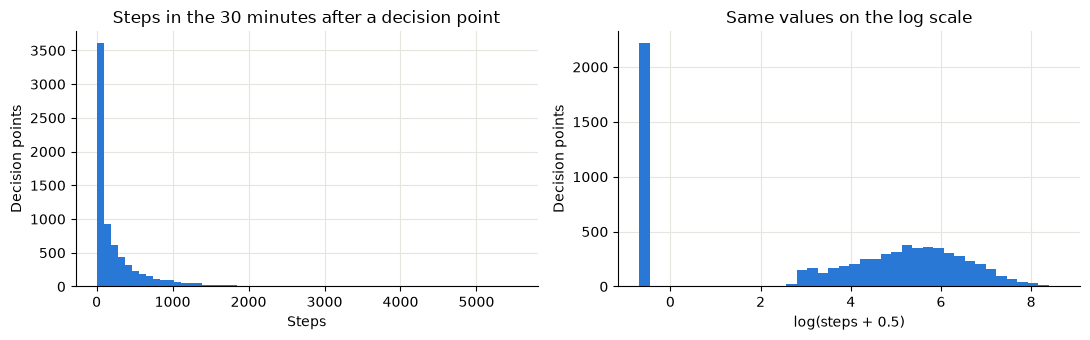

In [15]:
steps = sugg["jbsteps30"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(steps, bins=60, color=BLUE)
axes[0].set(title="Steps in the 30 minutes after a decision point", xlabel="Steps", ylabel="Decision points")
axes[1].hist(np.log(steps + 0.5), bins=40, color=BLUE)
axes[1].set(title="Same values on the log scale", xlabel="log(steps + 0.5)", ylabel="Decision points")
plt.tight_layout()
plt.show()

- 왼쪽 그래프는 막대가 0 근처에 몰려 있고, 오른쪽은 5,000보까지 길게 늘어져 있음. 
- 대부분의 값이 0~500보 사이인데, 몇개 수천 보 때문에 가로축이 길어져서 정작 많은 값들의 모양이 안 보임.
- 큰 값의 간격을 줄여 주는 변환, 0의 로그는 계산 불가. 걸음 수에는 0이 많아서, 모든 값에 0.5를 더한 뒤 로그를 씌움.
- Step counts have many zeros and a long right tail (mean 276, median 94). The log scale spreads them out.

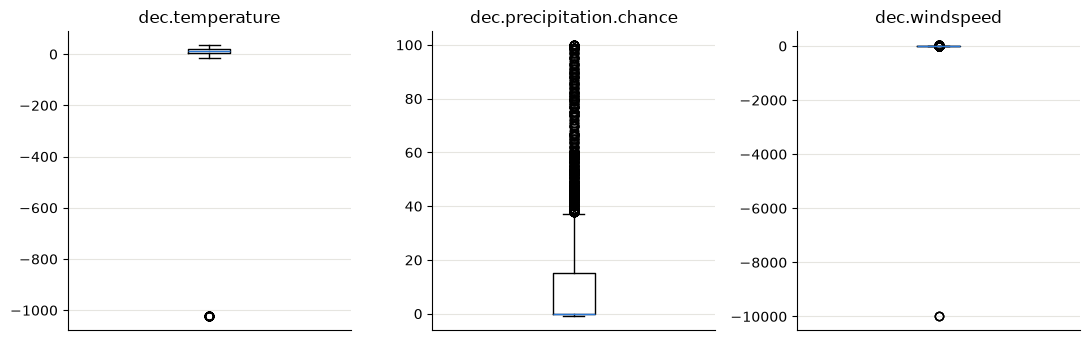

In [16]:
weather_cols = ["dec.temperature", "dec.precipitation.chance", "dec.windspeed"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, col in zip(axes, weather_cols):
    ax.boxplot(sugg_num[col].dropna(), medianprops={"color": BLUE})
    ax.set(title=col, xticks=[])
plt.tight_layout()
plt.show()

In [17]:
# Values that cannot be real readings
invalid = {
    "dec.temperature": sugg_num["dec.temperature"] < -50,                  # colder than -50°C
    "dec.precipitation.chance": sugg_num["dec.precipitation.chance"] < 0,  # a probability below 0
    "dec.windspeed": sugg_num["dec.windspeed"] < 0,                        # a wind speed below 0
}

for col, is_invalid in invalid.items():
    print(sugg_num.loc[is_invalid, col].value_counts().to_string())
    print()

dec.temperature
-1024.0    35

dec.precipitation.chance
-1.0    42

dec.windspeed
-1.0       35
-9999.0     3



- The weather minimums are placeholder codes: temperature -1024, precipitation chance -1, wind speed -9999. 
- They appear as points far from the real values in the box plots.

### 1-3. Categorical values

- From the boolean, ordinal, and nominal columns, pick the ones used in the analysis. 
- The location category has hundreds of values, so only the top 10 are shown.

In [19]:
for col in ["avail", "send", "send.active", "sugg.select.slot", "response", "recognized.activity", "dec.weather.condition"]:
    print(sugg[col].value_counts(dropna=False))
    print()

avail
True     6590
False    1684
Name: count, dtype: int64

send
True     3918
False    3621
NaN       735
Name: count, dtype: int64

send.active
False    6084
True     2189
NaN         1
Name: count, dtype: int64

sugg.select.slot
4    1658
2    1657
3    1656
5    1654
1    1649
Name: count, dtype: int64

response
NaN                     5253
good                    1460
no_response              958
bad                      570
snoozed_for_4_hours       32
snoozed_for_12_hours       1
Name: count, dtype: int64

recognized.activity
STILL                6335
NaN                   735
IN_VEHICLE            552
ON_FOOT               339
UNKNOWN               293
ON_BICYCLE             12
AUGMENTED_VEHICLE       8
Name: count, dtype: int64

dec.weather.condition
Overcast                                                                                       2474
Clear                                                                                          2424
Partly Cloudy                

- Weather contains `unknown` and system error text (`com.google...`).
- There are over 200 location categories, so they need to be grouped into home, work, and other.
- `recognized.activity` is mostly `STILL`, because notifications were not sent while walking or driving.

In [20]:
print("Different location categories:", sugg["dec.location.category"].nunique())
sugg["dec.location.category"].value_counts(dropna=False).head(10)

Different location categories: 228


dec.location.category
home                                                       1852
work                                                       1092
NaN                                                         735
university,point_of_interest,establishment                  563
store,point_of_interest,establishment                       554
electronics_store,store,point_of_interest,establishment     411
park,point_of_interest,establishment                        406
restaurant,food,point_of_interest,establishment             249
unknown                                                     116
clothing_store,store,point_of_interest,establishment        110
Name: count, dtype: int64

### 1-4. Does the file match the study design?
- Before building the table, check four things: no duplicates, notifications at about 60% of available decision points, which time-slot column to use, and how many travel days there are.

In [ ]:
print("Duplicate (user, decision) rows:", sugg.duplicated(["user.index", "decision.index"]).sum()) # 행 중복 확인
print()
print("Decision points per user:")
print(sugg.groupby("user.index").size().describe().round(0))

Duplicate (user, decision) rows: 0

Decision points per user:
count     37.0
mean     224.0
std       24.0
min      175.0
25%      211.0
50%      215.0
75%      228.0
max      309.0
dtype: float64


In [22]:
pd.crosstab(sugg["avail"], sugg["send"].fillna("missing"), margins=True)

send,False,True,missing,All
avail,,,,
False,946,3,735,1684
True,2675,3915,0,6590
All,3621,3918,735,8274


- 세로(행) = avail: 알림을 받을 수 있는 상태였는가 (True/False)
- 가로(열) = send: 알림을 실제로 보냈는가 (True/False/missing)

In [23]:
sent_share = (sugg.loc[sugg["avail"], "send"] == True).mean()
print(f"Share of available decision points that got a notification: {sent_share:.3f} (design: 0.6)")

Share of available decision points that got a notification: 0.594 (design: 0.6)


- 59.4% of available decision points got a notification, matching the design (60%). 
- The 3 notifications sent while not available (`avail = False`) are errors; the analysis uses available decision points only, so they drop out.

In [ ]:
# 시간대 나타내는 두 열이 서로 일치하는지 확인

pd.crosstab(sugg["sugg.select.slot"], sugg["sugg.decision.slot"].fillna(-1)) 

sugg.decision.slot,-1.0,0.0,1.0,2.0,3.0,4.0,5.0,6.0
sugg.select.slot,,,,,,,,
1,147,17,1483,1,1,0,0,0
2,150,1,18,1486,0,2,0,0
3,137,0,0,16,1500,1,0,2
4,154,0,0,0,21,1481,0,2
5,147,1,0,0,1,12,1493,0


- `sugg.decision.slot` has missing (-1) and impossible values (0, 6). `sugg.select.slot`, the slot the user scheduled, is always 1 to 5, so the analysis uses it.

#### Summary of suggestions.csv
- One row per decision point, no duplicates; randomization matches the design.
- To do when building the table: log-transform steps, set weather codes to missing, group locations into three, use `sugg.select.slot`, flag travel days (390).

---

## 2. users.csv: Participants

### 2-1. Preview and column types

In [25]:
users = pd.read_csv(RAW_DIR / "users.csv")
print(users.shape)
users.head()

(37, 117)


,user.index,intake.survey.utime,intake.survey.tz,intake.survey.gmtoff,first.notif.utime,first.steps.utime,exit.survey.utime,exit.survey.tz,exit.survey.gmtoff,last.notif.utime,last.steps.utime,travel.start,travel.end,dropout.date,totaldays,own.phone,age,gender,marital,marother,ethnicity,ethother,household.size,children,childhome,occupation,education,vacation,screentime,sms,messaging,call,email,calendar,web,social,other.mobile,fitapp,fitapp.names,fittracker,fittracker.names,phonecomfort,compcomfort,office.shops,office.pleasant,office.sidewalk,consc.detail,consc.prepared,consc.carryplans,consc.startwork,consc.wastetime,consc.duties,consc.makeplans,consc,stairs.intake,walk.intake,parkfar.intake,workoutbreaks.intake,stand.intake,stairs.exit,walk.exit,parkfar.exit,workoutbreaks.exit,stand.exit,selfeff.tired.intake,selfeff.badmood.intake,selfeff.notime.intake,selfeff.vaca.intake,selfeff.precip.intake,selfeff.intake,selfeff.tired.exit,selfeff.badmood.exit,selfeff.notime.exit,selfeff.vaca.exit,selfeff.precip.exit,selfeff.exit,house,shopshome,transithome,sidewalkhome,canbike,recfacilities,unsafenight,trafficwalk,seeactive,interest,motor,intersections,sidewalkgood,bikegood,trafficbike,unsafeday,placeshome,vigact.days.intake,modact.days.intake,walk10.days.intake,sit.time.intake,vigact.time.intake,modact.time.intake,walk.time.intake,vigact.metmins.intake,modact.metmins.intake,walk.metmins.intake,metmins.intake,ipaq.hepa.intake,vigact.days.exit,modact.days.exit,walk10.days.exit,sit.time.exit,vigact.time.exit,modact.time.exit,walk.time.exit,vigact.metmins.exit,modact.metmins.exit,walk.metmins.exit,metmins.exit,ipaq.hepa.exit
0,1,2015-07-22 14:34:03,Etc/GMT+4,-14400,2015-07-22 16:31:53,2015-07-22 16:42:00,2015-09-15 06:00:00,Etc/GMT+4,-14400,2015-09-15 21:31:27,2015-09-14 14:03:00,2015-08-12,2015-08-31,NaN,35,True,48,female,married,NaN,white/caucasian,NaN,2,1,0,program coordinator,some college,not sure,2,yes,no,yes,yes,no,no,yes,"internet, games",yes,"MyFitnessPal, MapMyRun",no,NaN,4,4,1,1,1,4,4,5,1,1,2,4,21,4,4,3,3,3,3.0,3.0,4.0,4.0,3.0,3,4,3,5,4,19,4.0,4.0,4.0,4.0,4.0,20.0,1,4,4,4,4,4,1,1,4,4.0,1,3,4,4,2,1,4,2,2,7.0,360.0,120,120.0,45.0,1920,960.0,1039.5,3919.5,3,5.0,5.0,7.0,NaN,120.0,90.0,240.0,4800.0,1800.0,5544.0,12144.0,3.0
1,2,2015-07-24 14:46:56,Etc/GMT+4,-14400,2015-07-24 17:01:56,2015-07-24 17:38:00,2015-09-04 07:00:00,Etc/GMT+4,-14400,2015-09-04 00:31:38,2015-09-04 00:24:00,NaN,NaN,NaN,41,False,28,male,married,NaN,asian/pacific islander,NaN,2,0,0,student,grad degree,not sure,2,yes,yes,yes,yes,yes,yes,yes,banking,yes,S Health,no,NaN,5,5,1,1,1,5,4,4,2,3,3,4,25,3,3,4,2,2,4.0,4.0,3.0,3.0,2.0,4,4,2,1,1,12,4.0,3.0,1.0,2.0,1.0,11.0,2,4,4,4,4,4,1,1,4,3.0,1,3,4,4,1,1,4,0,0,7.0,600.0,0,0.0,61.0,0,0.0,1409.1,1409.1,2,0.0,0.0,7.0,600.0,0.0,0.0,40.0,0.0,0.0,924.0,924.0,2.0
2,3,2015-07-25 17:40:12,Etc/GMT+4,-14400,2015-07-25 18:31:35,2015-07-25 20:03:00,2015-09-14 07:45:00,Etc/GMT+4,-14400,2015-09-14 15:21:04,2015-09-14 15:20:00,2015-08-13,2015-08-20,NaN,44,True,20,female,single,NaN,white/caucasian,NaN,3,0,0,"student, intern",some college,yes,1,yes,no,yes,yes,yes,yes,yes,"games, music",yes,NikeRunning,yes,FitBit,5,5,2,1,1,5,4,4,2,2,2,4,23,4,4,4,3,3,4.0,4.0,5.0,3.0,3.0,2,3,2,3,4,14,3.0,4.0,2.0,4.0,5.0,18.0,4,4,4,4,4,4,1,1,4,3.0,3,4,4,3,2,1,4,4,5,7.0,600.0,60,20.0,20.0,1920,400.0,462.0,2782.0,3,4.0,7.0,7.0,360.0,60.0,30.0,30.0,1920.0,840.0,693.0,3453.0,3.0
3,4,2015-07-27 13:57:23,Etc/GMT+4,-14400,2015-07-27 18:32:19,2015-07-27 18:37:00,2015-09-09 12:30:00,Etc/GMT+4,-14400,2015-09-08 23:01:26,2015-09-08 22:58:00,NaN,NaN,NaN,43,False,21,male,single,NaN,american indian,NaN,4,0,0,"engineering intern, lifegaurd",some college,no,2,yes,yes,no,yes,yes,no,no,"music, checklists",no,NaN,no,NaN,5,5,1,1,1,5,4,5,1,1,1,5,22,5,5,4,5,5,5.0,4.0,2.0,5.0,5.0,2,4,5,5,5,21,4.0,5.0,3.0,5.0,5.0,22.0,3,4,4,4,4,3,1,1,2,3.0,1,3,3,3,1,1,3,6,7,7.0,600.0,60,180.0,45.0,2880,5040.0,1039.5,8959.5,3,6.0,7.0,7.0,420.0,90.0,90.0,60.0,4320.0,2520.0,1386.0,8226.0,3.0
4,5,2015-07-27 16

In [ ]:

print(users.dtypes.value_counts()) # 자료형 개수
print()
print("Same participants as suggestions.csv:", set(users["user.index"]) == set(sugg["user.index"]))
print("Dropped out early:", users["dropout.date"].notna().sum())
print("Had a travel period:", users["travel.start"].notna().sum())

int64      54
str        31
float64    31
bool        1
Name: count, dtype: int64

Same participants as suggestions.csv: True
Dropped out early: 4
Had a travel period: 7


### 2-2. Numeric distributions
- Focus on variables later analyses may use: age, days in the study, self-efficacy, and usual activity.

In [29]:
user_num_cols = ["age", "totaldays", "selfeff.intake", "metmins.intake"]
users[user_num_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,37.0,35.5,14.2,19.0,24.0,28.0,47.0,64.0
totaldays,37.0,41.8,5.5,16.0,41.0,43.0,44.0,51.0
selfeff.intake,37.0,14.5,3.3,8.0,12.0,14.0,17.0,21.0
metmins.intake,31.0,2565.8,3129.9,0.0,852.5,1409.1,2832.0,13080.0


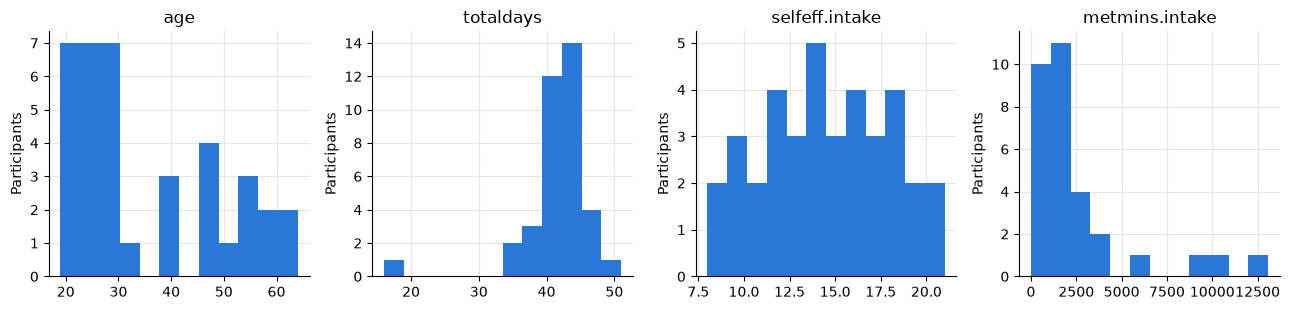

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, col in zip(axes, user_num_cols):
    ax.hist(users[col].dropna(), bins=12, color=BLUE)
    ax.set(title=col, ylabel="Participants")
plt.tight_layout()
plt.show()

### 2-3. Cataegorical values

In [31]:
for col in ["gender", "education", "ipaq.hepa.intake", "screentime"]:
    print(users[col].value_counts(dropna=False))
    print()

gender
female    24
male      13
Name: count, dtype: int64

education
grad degree         14
college grad        12
some college         6
some grad school     5
Name: count, dtype: int64

ipaq.hepa.intake
2    15
3    11
1    11
Name: count, dtype: int64

screentime
2    18
1    17
3     2
Name: count, dtype: int64



#### Summary of users.csv
- Both files have the same 37 participants; 4 dropped out early and 7 had travel periods.
- Median age 28; most stayed about six weeks. Usual activity (`metmins.intake`) is missing for 6 and right-skewed.
- `ipaq.hepa.intake` (1-3) and `screentime` (1-6) are categories stored as numbers, so they are counted, not averaged.

---

## 3. jbsteps.csv: Jawbone steps
- Minute-level steps from the wrist tracker; each row is one minute with steps. 
- The outcome, steps in the 30 minutes after a decision point (`jbsteps30`), was computed from these records and is already in `suggestions.csv`.

### 3-1. Preview and Column types

In [32]:
jb = pd.read_csv(RAW_DIR / "jbsteps.csv")
print(jb.shape)
jb.head()

(237865, 10)


,user.index,steps.utime,steps.utime.local,steps,decision.index,slot,study.day.nogap,decision.index.following.dec,slot.following.dec,study.day.nogap.following.dec
0,1,2015-07-22 14:54:00,2015-07-22 10:54:00,19,NaN,NaN,NaN,0.0,2.0,0.0
1,1,2015-07-22 14:55:00,2015-07-22 10:55:00,48,NaN,NaN,NaN,0.0,2.0,0.0
2,1,2015-07-22 14:56:00,2015-07-22 10:56:00,109,NaN,NaN,NaN,0.0,2.0,0.0
3,1,2015-07-22 14:57:00,2015-07-22 10:57:00,6,NaN,NaN,NaN,0.0,2.0,0.0
4,1,2015-07-22 15:04:00,2015-07-22 11:04:00,58,NaN,NaN,NaN,0.0,2.0,0.0


In [33]:
jb.info()

<class 'pandas.DataFrame'>
RangeIndex: 237865 entries, 0 to 237864
Data columns (total 10 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   user.index                     237865 non-null  int64  
 1   steps.utime                    237865 non-null  str    
 2   steps.utime.local              237865 non-null  str    
 3   steps                          237865 non-null  int64  
 4   decision.index                 237093 non-null  float64
 5   slot                           237093 non-null  float64
 6   study.day.nogap                237093 non-null  float64
 7   decision.index.following.dec   235444 non-null  float64
 8   slot.following.dec             235444 non-null  float64
 9   study.day.nogap.following.dec  235444 non-null  float64
dtypes: float64(6), int64(2), str(2)
memory usage: 18.1 MB


### 3-2. Steps per minute and per day

In [34]:
jb["steps"].describe().round(1)

count    237865.0
mean         54.5
std          37.1
min           1.0
25%          24.0
50%          43.0
75%          81.0
max         206.0
Name: steps, dtype: float64

In [35]:
# Daily steps: add up each user's minutes on each local date

jb_date = pd.to_datetime(jb["steps.utime.local"]).dt.date
jb_daily = jb.groupby(["user.index", jb_date])["steps"].sum().rename("daily_steps").reset_index()
jb_daily["daily_steps"].describe().round(0)

count     1612.0
mean      8037.0
std       5216.0
min         18.0
25%       4354.0
50%       7242.0
75%      10823.0
max      43642.0
Name: daily_steps, dtype: float64

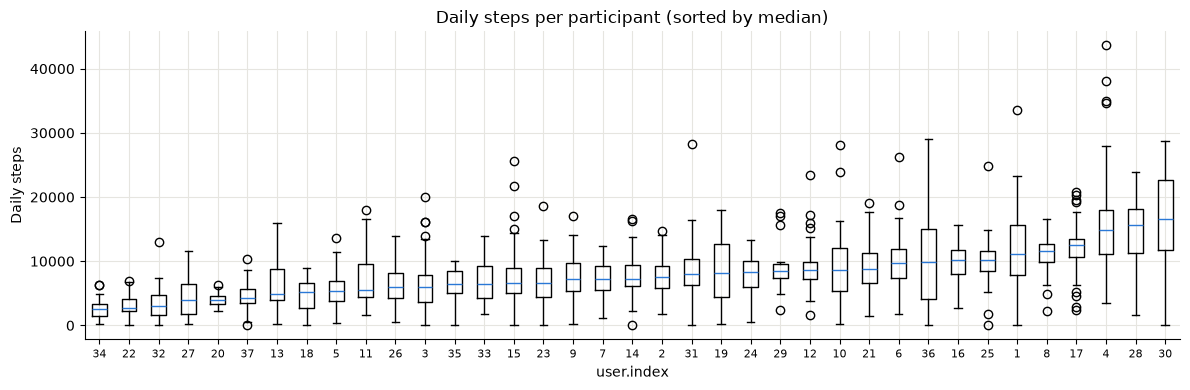

In [ ]:
## 참가자마다 하루 걸음 수가 얼마나 다른지

order = jb_daily.groupby("user.index")["daily_steps"].median().sort_values().index # 사용자별 하루 걸음 수의 중앙값

fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot([jb_daily.loc[jb_daily["user.index"] == u, "daily_steps"] for u in order], medianprops={"color": BLUE})
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, fontsize=8)
ax.set(title="Daily steps per participant (sorted by median)", xlabel="user.index", ylabel="Daily steps")
plt.tight_layout()
plt.show()

#### Summary of jbsteps.csv
- about 8,000 steps a day on average.
- Daily steps differ a lot between participants (medians from about 2,500 to 16,000). 
- Observations from the same person are alike, so later analyses group them by person.

---

## 4. gfsteps.csv: Phone steps
- Steps measured by the phone's accelerometer, with the same structure as `jbsteps.csv`. 
- Compared with Jawbone to decide which device the outcome should use.

In [37]:
gf = pd.read_csv(RAW_DIR / "gfsteps.csv")
print(gf.shape)
print("Participants with phone steps:", gf["user.index"].nunique(), "of", users.shape[0])
gf.head()

(197524, 7)
Participants with phone steps: 27 of 37


,user.index,steps.utime,steps,decision.index,slot,decision.index.following.dec,slot.following.dec
0,1,2015-07-22 14:52:49.555227,1,NaN,NaN,0.0,2.0
1,1,2015-07-22 14:53:49.555227,55,NaN,NaN,0.0,2.0
2,1,2015-07-22 14:54:24.957986,1,NaN,NaN,0.0,2.0
3,1,2015-07-22 14:54:25.360817,100,NaN,NaN,0.0,2.0
4,1,2015-07-22 14:55:25.913032,1,NaN,NaN,0.0,2.0


In [38]:
# 분당 걸음 수와 하루 걸음 수

gf_date = pd.to_datetime(gf["steps.utime"]).dt.date  # no local-time column, so UTC dates
gf_daily = gf.groupby(["user.index", gf_date])["steps"].sum()

pd.DataFrame({
    "steps per minute": gf["steps"].describe(),
    "daily steps": gf_daily.describe(),
}).round(1)

,steps per minute,daily steps
count,197524.0,1127.0
mean,27.2,4759.3
std,88.4,4341.0
min,1.0,1.0
25%,1.0,1639.5
50%,4.0,3824.0
75%,27.0,6615.5
max,4929.0,39083.0


#### Summary of gfsteps.csv
- Only 27 of 37 participants have records.
- A maximum of 4,929 steps per minute is not humanly possible; several minutes seem to be lumped into one row.
- Daily steps are much lower than Jawbone's, because the phone misses steps when it is not carried.
- So the outcome uses Jawbone steps.

## 5. Build the analysis table
- Clean `suggestions.csv` as decided in section 1. 
- One row per decision point; columns are built in five groups.

### 5-1. Identifiers and time
- `sugg.decision.utime` is in UTC and `sugg.gmtoff` is the offset from UTC in seconds. 
- Convert to local time to get the weekday and study day.

In [ ]:
# 테이블 만들기
decision_points = pd.DataFrame({
    "user_id": sugg["user.index"],
    "decision_id": sugg["decision.index"],
})


utc_time = pd.to_datetime(sugg["sugg.decision.utime"]) # 날짜형으로
decision_points["decision_time_local"] = utc_time + pd.to_timedelta(sugg["sugg.gmtoff"], unit="s") # 현지시각으로 전환

# Study day: days since the user's first decision point (연구 일차와 주차)
local_date = decision_points["decision_time_local"].dt.normalize()
first_date = local_date.groupby(decision_points["user_id"]).transform("min")
decision_points["study_day"] = (local_date - first_date).dt.days.astype("Int64")
decision_points["study_week"] = (decision_points["study_day"] // 7).astype("Int64")

# 시간대
decision_points["slot"] = sugg["sugg.select.slot"]
decision_points["slot_name"] = decision_points["slot"].map({
    1: "morning commute", 2: "lunch", 3: "mid-afternoon", 4: "evening commute", 5: "after dinner",
})
decision_points["weekday"] = decision_points["decision_time_local"].dt.day_name() # 요일
decision_points["is_weekend"] = decision_points["weekday"].isin(["Saturday", "Sunday"]).astype("Int64").where(decision_points["weekday"].notna()) # .isin은 빈 값을 False로 처리(없으면 시각모르는 날 평일로 들어감), 주말 True

decision_points.head()

,user_id,decision_id,decision_time_local,study_day,study_week,slot,slot_name,weekday,is_weekend
0,1,0,2015-07-22 12:31:53,0,0,2,lunch,Wednesday,0
1,1,1,2015-07-22 14:32:10,0,0,3,mid-afternoon,Wednesday,0
2,1,2,2015-07-22 17:31:48,0,0,4,evening commute,Wednesday,0
3,1,3,2015-07-22 19:31:50,0,0,5,after dinner,Wednesday,0
4,1,4,2015-07-23 05:31:31,1,0,1,morning commute,Thursday,0


### 5-2. Availability, sending, notification type
- The one notification that was sent but has no recorded type is marked `unknown`.

In [ ]:
decision_points["available"] = sugg["avail"].astype(int) # True = 1, False = 0
decision_points["sent"] = (sugg["send"] == True).astype(int) # 발송여부, 빈값 735(서버 끊김), False와 빈값 모두 0으로 두기
decision_points["send_type"] = np.select(
    [sugg["send.active"] == True, sugg["send.sedentary"] == True, decision_points["sent"] == 1], # decision_points["sent"] == 1 보냈지만 종류 기록x
    ["active", "sedentary", "unknown"],
    default="none", # 알림 보내지 않음
)
decision_points["travel_day"] = sugg["decision.index.nogap"].isna().astype(int) # 여행일이면 True
decision_points["is_prefetch"] = sugg["is.prefetch"].map({True: 1, False: 0}).astype("Int64") # True면 서버 연결이 끊겨서 30분 전에 미리 받아 둔 맥락(위치, 날씨 등)으로 결정한 시점

decision_points["send_type"].value_counts()

send_type
none         4356
active       2189
sedentary    1728
unknown         1
Name: count, dtype: int64

### 5-3. Context at the decision point
- All of this is known before a notification is sent. 
- Locations become three groups, weather codes become missing, and weather is grouped into clear, cloudy, and precipitation. 
- `screen_on` is whether an app was open at the decision point (the raw value is empty when the screen was off).

In [42]:
def simplify_location(category):
    if pd.isna(category) or category == "unknown": # 빈값 or unkown이면 빈칸으로 두기
        return np.nan
    if category in ("home", "work"):
        return category
    return "other" # 이외는 other로 묶음


PRECIPITATION = { # 비, 눈 날씨 목록
    "Rain", "Light Rain", "Light Drizzle", "Snow", "Light Snow", "Ice Pellets",
    "Light Freezing Rain", "Thunderstorm", "Light Thunderstorms and Rain",
}


def group_weather(condition):
    if pd.isna(condition):
        return np.nan # 빈값은 빈값
    if condition == "Clear":
        return "clear" # 맑음은 그대로
    if condition in PRECIPITATION:
        return "precipitation"
    return "cloudy"

# 날씨 오류값 찾지
weather = sugg["dec.weather.condition"]
invalid_weather = (weather == "unknown") | weather.str.startswith("com.google", na=False)

# 열 만들기
decision_points["location"] = sugg["dec.location.category"].map(simplify_location)
decision_points["weather"] = weather.where(~invalid_weather) # 오류값 아니면 True
decision_points["weather_group"] = decision_points["weather"].map(group_weather)
decision_points["temperature_c"] = sugg["dec.temperature"].where(sugg["dec.temperature"] != -1024) # -1024는 빈값으로 두기
decision_points["precip_chance"] = sugg_num["dec.precipitation.chance"].where(sugg_num["dec.precipitation.chance"] >= 0)
decision_points["screen_on"] = sugg["front.end.application"].notna().astype("Int64").where(sugg["connect"]) # 앱이름 있으면 True / 연결 끊긴 시점 빈값으로 두기
decision_points["hours_since_phone_use"] = sugg["sugg.device.since"]

print(decision_points["location"].value_counts(dropna=False))
print()
print(decision_points["weather_group"].value_counts(dropna=False))

location
other    4479
home     1852
work     1092
NaN       851
Name: count, dtype: int64

weather_group
cloudy           4592
clear            2424
NaN               891
precipitation     367
Name: count, dtype: int64


### 5-4. Step counts
- The outcome is Jawbone steps in the 30 minutes after a decision point. 
- As seen in section 1.2 it is skewed, so it is transformed to log(steps + 0.5). 
- The `_zero` columns, with missing values replaced by 0, are kept for sensitivity checks.

In [43]:
decision_points["steps_pre30"] = sugg["jbsteps30pre"]
decision_points["steps_post30"] = sugg["jbsteps30"] # 결과 변수
decision_points["steps_pre30_zero"] = sugg["jbsteps30pre.zero"] # 빈값 0으로 채움
decision_points["steps_post30_zero"] = sugg["jbsteps30.zero"] # 빈값 0으로 채움

for col in ["steps_pre30", "steps_post30", "steps_pre30_zero", "steps_post30_zero"]:
    decision_points[f"log_{col}"] = np.log(decision_points[col] + 0.5)

decision_points[["steps_pre30", "steps_post30", "log_steps_post30"]].describe().round(1)

,steps_pre30,steps_post30,log_steps_post30
count,7262.0,7233.0,7233.0
mean,258.9,276.4,3.5
std,494.9,485.0,2.9
min,0.0,0.0,-0.7
25%,0.0,0.0,-0.7
50%,82.0,94.0,4.5
75%,292.0,333.0,5.8
max,5380.0,5527.0,8.6


### 5-5. Response
- `engaged` is 1 for good, bad, or snoozed, 0 for no response, and missing when no notification was sent or nothing was recorded.

In [44]:
decision_points["response"] = sugg["response"].str.replace(r"^snoozed.*", "snoozed", regex=True) # 알람 끄기 값을 하나로 합치기
decision_points["engaged"] = decision_points["response"].map({"good": 1, "bad": 1, "snoozed": 1, "no_response": 0}).astype("Int64") # 반응 여부, 반응O = 1, 반응X = 0

pd.crosstab(decision_points["response"].fillna("(missing)"), decision_points["sent"])

sent,0,1
response,,
(missing),4356,897
bad,0,570
good,0,1460
no_response,0,958
snoozed,0,33


## 6. Validate
- Each check stops the notebook with a message if something is wrong.

In [45]:
assert len(decision_points) == len(sugg), "Row count changed." # 행 개수
assert not decision_points.duplicated(["user_id", "decision_id"]).any(), "Duplicate (user_id, decision_id) rows." # 중복 없는지
assert decision_points["slot"].between(1, 5).all(), "Slot outside 1 to 5." # 모두 True여야 True
assert ((decision_points["send_type"] == "none") == (decision_points["sent"] == 0)).all(), "send_type does not match sent."
assert decision_points.loc[decision_points["sent"] == 0, "engaged"].isna().all(), "engaged is set for a notification that was not sent."
assert decision_points["temperature_c"].dropna().between(-40, 50).all(), "Temperature outside a plausible range."
assert decision_points["precip_chance"].dropna().between(0, 100).all(), "Precipitation chance outside 0 to 100."
assert decision_points["available"].sum() == sugg["avail"].sum(), "Available count differs from the raw file."
assert decision_points["sent"].sum() == (sugg["send"] == True).sum(), "Sent count differs from the raw file."

print("All checks passed.")

All checks passed.


## 7. Analysis Samples

Later notebooks filter `decision_points.csv` with these rules.
- **Effect analysis (03, 04)**: available, not a travel day, outcome observed
- **Engagement analysis (05, 06)**: available, not a travel day, notification sent, response recorded

In [46]:
base = (decision_points["available"] == 1) & (decision_points["travel_day"] == 0) # 가용상태, 여행X 상태
effect_sample = base & decision_points["steps_post30"].notna() # 알림 후 걸음수 있는 경우
engagement_sample = base & (decision_points["sent"] == 1) & decision_points["engaged"].notna() # 알림 보냈다, 반응 기록이 있다

print("Effect sample:", effect_sample.sum(), "| of which sent:", (effect_sample & (decision_points["sent"] == 1)).sum()) # 효과 분석 표본의 건수
print("Engagement sample:", engagement_sample.sum(), "| engagement rate:", round(decision_points.loc[engagement_sample, "engaged"].mean(), 3)) # 반응 분석 표본의 건수

Effect sample: 5746 | of which sent: 3405
Engagement sample: 2909 | engagement rate: 0.685


## 8. Save
Save the table together with a description of its columns (`data_dictionary.md`).

In [47]:
DATA_DICTIONARY = [
    ("user_id", "User ID", "user.index"),
    ("decision_id", "Decision point ID within a user", "decision.index"),
    ("decision_time_local", "Decision time in local time", "sugg.decision.utime + sugg.gmtoff (seconds)"),
    ("study_day", "Days since the user's first decision point (0 = first day)", "decision_time_local"),
    ("study_week", "study_day // 7 (0 = first week)", "study_day"),
    ("slot", "Scheduled daily time slot, 1 to 5", "sugg.select.slot"),
    ("slot_name", "morning commute, lunch, mid-afternoon, evening commute, after dinner", "slot"),
    ("weekday", "Day of the week (local time)", "decision_time_local"),
    ("is_weekend", "1 = Saturday or Sunday", "weekday"),
    ("available", "1 = connected, not snoozed, not in transit", "avail"),
    ("sent", "1 = notification sent", "send"),
    ("send_type", "active, sedentary, none, or unknown (sent, type not recorded)", "send.active, send.sedentary"),
    ("travel_day", "1 = travel day excluded by the study", "decision.index.nogap is missing"),
    ("is_prefetch", "1 = context taken 30 minutes before the decision", "is.prefetch"),
    ("location", "home, work, or other (missing if unknown)", "dec.location.category"),
    ("weather", "Weather condition (missing if unknown or a system error)", "dec.weather.condition"),
    ("weather_group", "clear, cloudy (incl. fog and haze), or precipitation", "weather"),
    ("temperature_c", "Temperature in Celsius (-1024 set to missing)", "dec.temperature"),
    ("precip_chance", "Chance of precipitation in 60 minutes, 0-100 (-1 and unknown set to missing)", "dec.precipitation.chance"),
    ("screen_on", "1 = an app was open at the decision point (missing if not connected)", "front.end.application"),
    ("hours_since_phone_use", "Hours since the last phone use before the decision point", "sugg.device.since"),
    ("steps_pre30", "Jawbone steps in the 30 minutes before", "jbsteps30pre"),
    ("steps_post30", "Jawbone steps in the 30 minutes after (main outcome)", "jbsteps30"),
    ("steps_pre30_zero", "steps_pre30 with missing set to 0", "jbsteps30pre.zero"),
    ("steps_post30_zero", "steps_post30 with missing set to 0", "jbsteps30.zero"),
    ("log_steps_pre30", "log(steps_pre30 + 0.5)", "steps_pre30"),
    ("log_steps_post30", "log(steps_post30 + 0.5)", "steps_post30"),
    ("log_steps_pre30_zero", "log(steps_pre30_zero + 0.5)", "steps_pre30_zero"),
    ("log_steps_post30_zero", "log(steps_post30_zero + 0.5)", "steps_post30_zero"),
    ("response", "good, bad, snoozed, no_response, or missing", "response"),
    ("engaged", "1 = good, bad, or snoozed; 0 = no_response; missing if not sent or not recorded", "response"),
]
assert [row[0] for row in DATA_DICTIONARY] == list(decision_points.columns), "The data dictionary does not match the table."


# 파일 저장
PROCESSED_DIR.mkdir(exist_ok=True)
decision_points.to_csv(PROCESSED_DIR / "decision_points.csv", index=False)

lines = ["# Data dictionary: decision_points.csv", "", "| column | description | source |", "| --- | --- | --- |"]
lines += [f"| {col} | {desc} | {src} |" for col, desc, src in DATA_DICTIONARY]
(PROCESSED_DIR.parent.parent / "data_dictionary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

print("Saved decision_points.csv:", decision_points.shape)
print("Saved data_dictionary.md:", len(DATA_DICTIONARY), "columns")

Saved decision_points.csv: (8274, 31)
Saved data_dictionary.md: 31 columns
